# FracAtlas release: ONNX export and Hugging Face upload (CPU)

Companion notebook for [MHKhan50/fracatlas-fracture-benchmark](https://github.com/MHKhan50/fracatlas-fracture-benchmark).
It takes the output of the training notebook, exports the ConvNeXt-Tiny classifier (the seed chosen on validation
AUROC) and the YOLO11s detector to ONNX, checks the export against PyTorch, and fits the temperature and threshold
of that seed on validation data.

**Inputs (Add Input):** the output of the notebook *FracAtlas fracture detection: ConvNeXt, DINOv2 and YOLO*, and the
FracAtlas dataset used there. Accelerator: **None (CPU)**. Internet **on**.

The last cell publishes to Hugging Face only when `PUBLISH = True` and a Kaggle secret `HF_TOKEN` (write token) exists.

In [1]:
import os, subprocess, sys, glob
os.chdir("/kaggle/working")
if not os.path.exists("fracatlas-fracture-benchmark"):
    subprocess.run(["git", "clone", "-q", "https://github.com/MHKhan50/fracatlas-fracture-benchmark.git"], check=True)
os.chdir("fracatlas-fracture-benchmark")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[train]", "onnx", "onnxruntime", "huggingface_hub"], check=True)
print(subprocess.run(["git", "log", "--oneline", "-1"], capture_output=True, text=True).stdout)

b26411a Release: export the detector from a copy of its weights (Kaggle inputs are read-only)



## 1. Find the training run and the images

In [2]:
found = sorted(glob.glob("/kaggle/input/**/analysis.json", recursive=True))
assert found, "Attach the output of the training notebook (Add Input -> Your Work)."
REPORTS = os.path.dirname(found[0])
print("reports:", REPORTS, sorted(os.listdir(REPORTS)))
assert os.path.exists(REPORTS + "/weights/convnext_tiny_best.pt"), "weights missing in the attached output"
csv = sorted(glob.glob("/kaggle/input/**/dataset.csv", recursive=True))
assert csv, "Attach the FracAtlas dataset (it contains dataset.csv)."
IMAGES = os.path.dirname(csv[0])
print("images:", IMAGES)

reports: /kaggle/input/notebooks/muzammalhussain11/fracatlas-fracture-detection-convnext-dinov2-yo/reports ['analysis.json', 'analysis.md', 'fig_region_selective.pdf', 'fig_region_selective.png', 'runs', 'split.csv', 'weights']
images: /kaggle/input/datasets/muzammalhussain11/naam-fracatlas/FracAtlas-2


## 2. Export to ONNX, check against PyTorch, fit temperature and threshold on validation

In [3]:
subprocess.run([sys.executable, "-m", "fracatlas_bench.release", "--reports", REPORTS, "--out", "/kaggle/working/release"], check=True)
for f in sorted(os.listdir("/kaggle/working/release")):
    print(f, round(os.path.getsize("/kaggle/working/release/" + f) / 1e6, 1), "MB")

/kaggle/working/fracatlas-fracture-benchmark/src/fracatlas_bench/release.py:64: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, x, str(out), input_names=["image"], output_names=["logit"], opset_version=17,


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from '/kaggle/working/release/_yolo_export.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (18.3 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: export success ✅ 1.2s, saved as '/kaggle/working/release/_yolo_export.onnx' (36.1 MB)

Export complete (1.9s)
Results saved to /kaggle/working/release/_yolo_export.onnx
Predict:         yolo p

## 3. Near-duplicate check between splits (perceptual hashes; a few minutes)

{
  "hash": "64-bit DCT perceptual hash",
  "thresholds": [
    0,
    4,
    8,
    12
  ],
  "splits": {
    "val": {
      "images": 614,
      "distance_quantiles": {
        "0": 0.0,
        "1": 0.0,
        "5": 4.0,
        "25": 8.0,
        "50": 10.0
      },
      "with_train_neighbour_within": {
        "0": 23,
        "4": 65,
        "8": 208,
        "12": 415
      }
    },
    "test": {
      "images": 614,
      "distance_quantiles": {
        "0": 0.0,
        "1": 0.0,
        "5": 4.0,
        "25": 8.0,
        "50": 10.0
      },
      "with_train_neighbour_within": {
        "0": 20,
        "4": 54,
        "8": 225,
        "12": 424
      }
    }
  },
  "test_auroc": {
    "cnn": {
      "all": {
        "images": 614,
        "fractured": 109,
        "auroc": 0.8094740666727224,
        "auroc_ci95": [
          0.7630535970602401,
          0.8523762691080761
        ]
      },
      "without_within_0": {
        "images": 594,
        "fractured": 105,

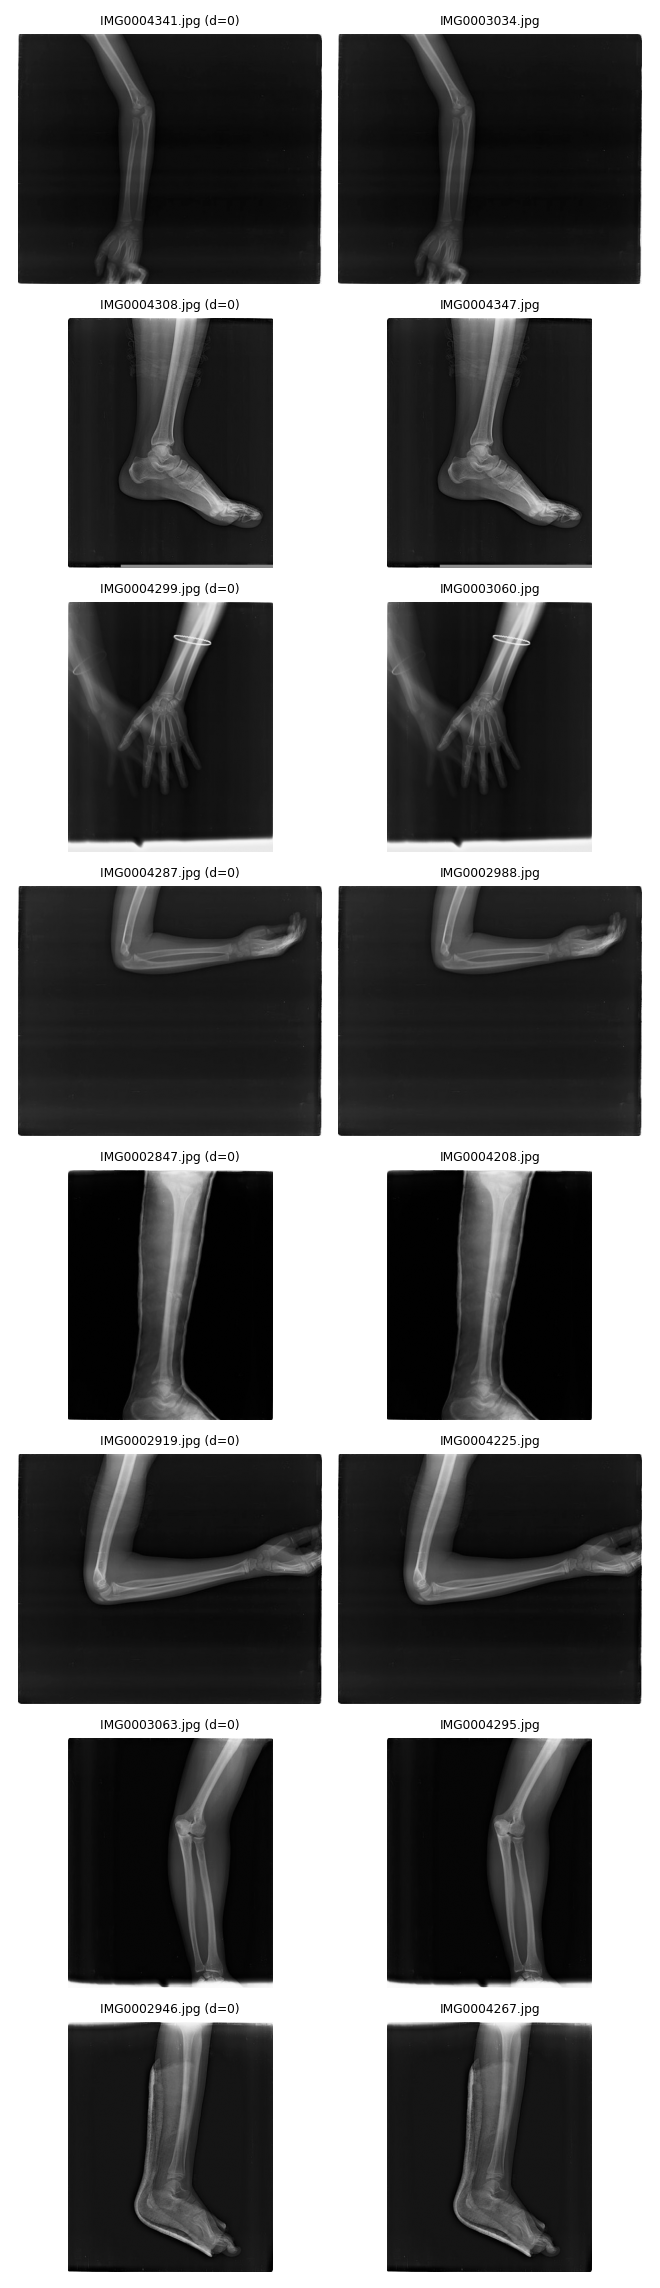

In [4]:
subprocess.run([sys.executable, "-m", "fracatlas_bench.neardup", "--images", IMAGES, "--reports", REPORTS,
                "--out", "/kaggle/working/neardup"], check=True)
from IPython.display import Image as Show
Show("/kaggle/working/neardup/closest_pairs.png")

## 4. Publish (only when you decide to)

In [5]:
PUBLISH = False   # set to True to create/update the public Hugging Face model and Space
if PUBLISH:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    subprocess.run([sys.executable, "scripts/publish_hf.py", "--release", "/kaggle/working/release",
                    "--split", REPORTS + "/split.csv", "--images", IMAGES], check=True)
else:
    print("Not published. Review /kaggle/working/release/config.json, then set PUBLISH = True and run this cell.")

Not published. Review /kaggle/working/release/config.json, then set PUBLISH = True and run this cell.
